# Notebook 03 — Target Construction

**Purpose:** Apply triple-barrier labelling to create the training targets.

This is the most critical step. We do NOT predict 'did the next bar close up or down?'
We predict: within 12 hours, does price hit TP (+ATR×1.5) or SL (−ATR×1.0) first?

**Prerequisite:** Notebook 02 must have run and saved `features/eurusd_features.csv`

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 5)

from src.targets import compute_triple_barrier_labels, summarise_labels, get_clean_training_set
from src.features import FEATURE_COLS

# Load the feature file built in notebook 02
df = pd.read_csv('../features/eurusd_features.csv', index_col=0, parse_dates=True)
print(f"Loaded features: {df.shape}")
print(f"Date range: {df.index[0].date()} -> {df.index[-1].date()}")

Loaded features: (39001, 26)
Date range: 2020-01-03 -> 2026-04-06


## Step 1 — Apply triple-barrier labels

Parameters:
- **TP** = entry price + ATR(14) × 1.5
- **SL** = entry price − ATR(14) × 1.0  
- **Time** = 12 bars (12 hours maximum hold)

These can be tuned later. Start with these defaults.

In [2]:
df_labelled = compute_triple_barrier_labels(
    df,
    n_tp=1.5,    # TP = 1.5 × ATR(14)
    n_sl=1.0,    # SL = 1.0 × ATR(14)
    t_bars=12,   # max 12 bars = 12 hours
    atr_col='atr_14'
)

print(f"\nLabelling complete.")
print(f"New columns added: {[c for c in df_labelled.columns if c not in df.columns]}")

Computing triple-barrier labels on 39,001 bars...
  TP = ATR × 1.5 | SL = ATR × 1.0 | Time = 12 bars (12H)

Labelling complete.
New columns added: ['label_raw', 'tp_price', 'sl_price', 'label_binary']


## Step 2 — Label summary

In [3]:
summarise_labels(df_labelled)


  Triple-barrier label summary
  Total bars          : 39,001
  TP hit (+1)         : 12,417  (31.8%)
  SL hit (-1)         : 18,459  (47.3%)
  Time-out (0)        : 8,125  (20.8%)
  Usable for training : 30,876  (79.2%)

  Class balance (TP / usable): 40.2% long wins
  [OK] Class balance is within acceptable range (40-60%).


## Step 3 — Get clean training set (remove time-outs)

In [4]:
X, y, df_clean = get_clean_training_set(df_labelled, FEATURE_COLS)

print(f"\nClean set shape:")
print(f"  X (features): {X.shape}")
print(f"  y (labels):   {y.shape}")
print(f"  Class 1 (TP hit / long win): {y.sum()} ({y.mean()*100:.1f}%)")
print(f"  Class 0 (SL hit / long loss): {(1-y).sum()} ({(1-y).mean()*100:.1f}%)")

  Clean training set: 30,876 rows (removed 8,125 time-outs and NaN rows)

Clean set shape:
  X (features): (30876, 20)
  y (labels):   (30876,)
  Class 1 (TP hit / long win): 12417 (40.2%)
  Class 0 (SL hit / long loss): 18459 (59.8%)


## Step 4 — Visualise labels on price chart

  Loading raw data files
  [OK] EURUSD 1H: 39,033 rows | 2020-01-01 → 2026-04-06
  [OK] EURUSD 4H: 39,033 rows | 2020-01-01 → 2026-04-06
  [OK] EURUSD Daily: 39,033 rows | 2020-01-01 → 2026-04-06
  [OK] DXY 1H: 39,033 rows | 2020-01-01 → 2026-04-06
  [OK] VIX Daily: 39,033 rows | 2020-01-01 → 2026-04-06
  [OK] US10Y Daily: 39,033 rows | 2020-01-01 → 2026-04-06
-------------------------------------------------------
  All files loaded successfully.


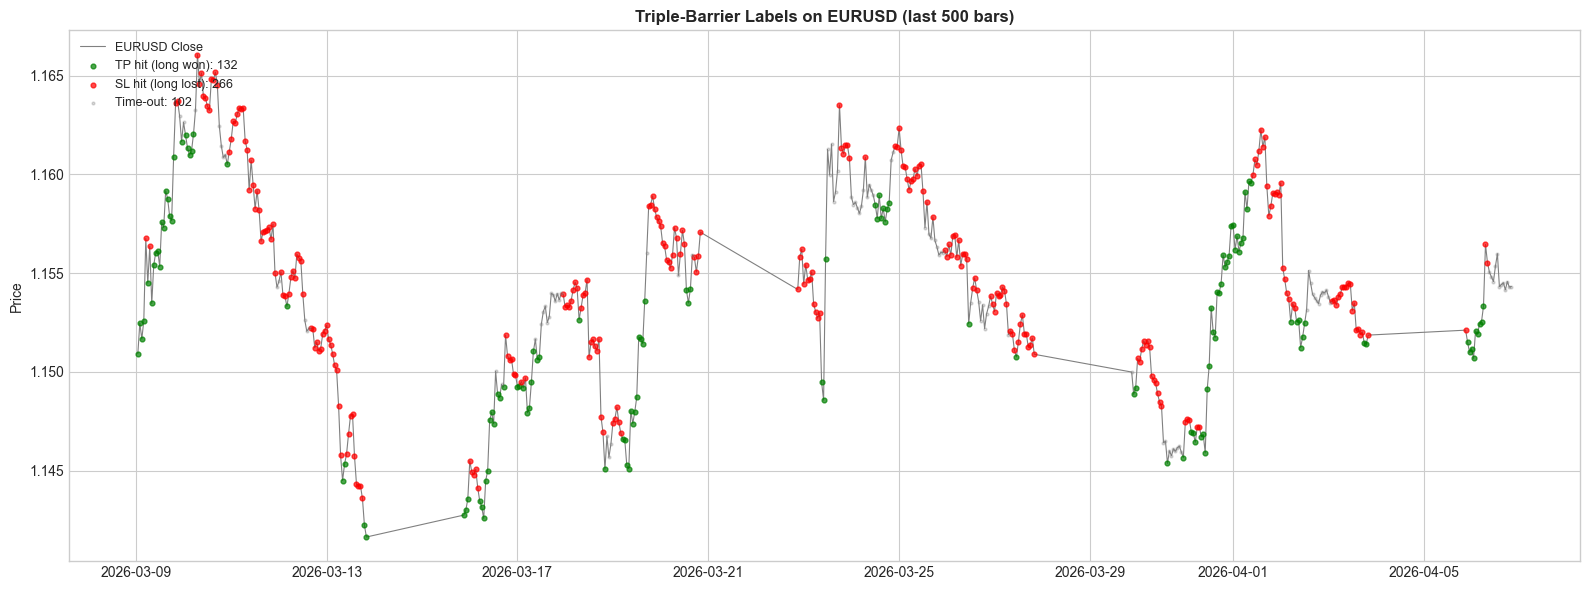

Saved to results/03_triple_barrier_labels.png


In [5]:
from src.data_loader import load_all_data
data = load_all_data()
eurusd_1h = data['eurusd_1h']

# Merge labels onto price for plotting
plot_df = eurusd_1h.join(df_labelled[['label_raw']], how='inner')
plot_df = plot_df.dropna(subset=['label_raw'])

# Use last 500 bars for clarity
sample = plot_df.tail(500)

fig, ax = plt.subplots(figsize=(16, 6))
ax.plot(sample.index, sample['Close'], color='gray', linewidth=0.8, label='EURUSD Close', zorder=1)

tp_bars = sample[sample['label_raw'] == 1]
sl_bars = sample[sample['label_raw'] == -1]
to_bars = sample[sample['label_raw'] == 0]

ax.scatter(tp_bars.index, tp_bars['Close'], color='green',  s=12, alpha=0.7, zorder=2, label=f'TP hit (long won): {len(tp_bars)}')
ax.scatter(sl_bars.index, sl_bars['Close'], color='red',    s=12, alpha=0.7, zorder=2, label=f'SL hit (long lost): {len(sl_bars)}')
ax.scatter(to_bars.index, to_bars['Close'], color='gray',   s=4,  alpha=0.3, zorder=2, label=f'Time-out: {len(to_bars)}')

ax.set_title('Triple-Barrier Labels on EURUSD (last 500 bars)', fontweight='bold')
ax.set_ylabel('Price')
ax.legend(fontsize=9, loc='upper left')
plt.tight_layout()
plt.savefig('../results/03_triple_barrier_labels.png', dpi=120, bbox_inches='tight')
plt.show()
print("Saved to results/03_triple_barrier_labels.png")

## Step 5 — Rolling win rate (is signal quality stable over time?)

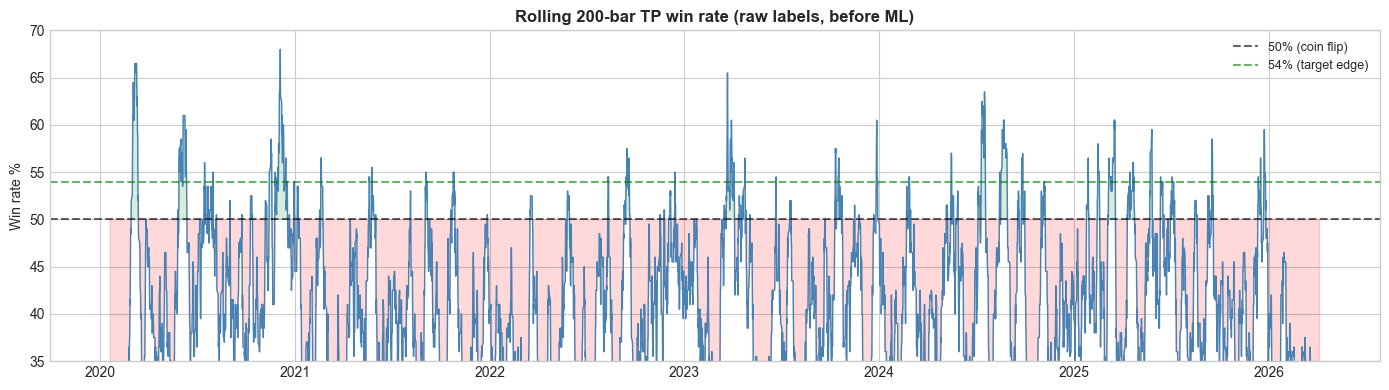

NOTE: This is the RAW win rate (just price statistics, no ML yet).
The ML model's job is to find the high-probability subsets above 54%.


In [6]:
# Rolling 200-bar win rate (TP hits / (TP + SL))
df_clean_sorted = df_clean.sort_index()
rolling_wr = df_clean_sorted['label_binary'].rolling(200).mean()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(rolling_wr.index, rolling_wr * 100, color='steelblue', linewidth=1.0)
ax.axhline(50, color='black',  linestyle='--', alpha=0.6, label='50% (coin flip)')
ax.axhline(54, color='green',  linestyle='--', alpha=0.6, label='54% (target edge)')
ax.fill_between(rolling_wr.index, 50, rolling_wr*100,
                where=(rolling_wr*100 > 50), alpha=0.15, color='green')
ax.fill_between(rolling_wr.index, 50, rolling_wr*100,
                where=(rolling_wr*100 < 50), alpha=0.15, color='red')
ax.set_title('Rolling 200-bar TP win rate (raw labels, before ML)', fontweight='bold')
ax.set_ylabel('Win rate %')
ax.set_ylim(35, 70)
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('../results/03_rolling_win_rate.png', dpi=120, bbox_inches='tight')
plt.show()
print("NOTE: This is the RAW win rate (just price statistics, no ML yet).")
print("The ML model's job is to find the high-probability subsets above 54%.")

## Step 6 — Save labelled dataset

In [7]:
df_clean.to_csv('../features/eurusd_labelled.csv')
print(f"Labelled dataset saved to features/eurusd_labelled.csv")
print(f"Shape: {df_clean.shape}")
print(f"\nThis file is used in notebooks 04, 05, and 06.")

Labelled dataset saved to features/eurusd_labelled.csv
Shape: (30876, 30)

This file is used in notebooks 04, 05, and 06.


## ✅ Checkpoint

**What to check before continuing:**

1. Usable rows (TP+SL) should be at least 5,000 rows
2. Class balance: TP hits should be between 35-65% (if wildly skewed, adjust n_tp/n_sl)
3. Rolling win rate chart should hover around 45-55% before ML — this is expected and healthy
4. `features/eurusd_labelled.csv` created successfully

**Understanding the label chart:**
- Green dots = bars where a long trade *would have* hit TP within 12H
- Red dots = bars where the SL *would have* been hit first
- Gray dots = time-outs (no decisive move in 12H) — these are excluded from training

**→ Open `04_model_training.ipynb` next.**